In [1]:
# Manejo y análisis de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# División de datos
from sklearn.model_selection import train_test_split

# Preprocesamiento
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Algoritmos de Machine Learning
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC

# Métricas de evaluación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Configuración para reproducibilidad
RANDOM_STATE = 42

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [2]:
from google.colab import files

uploaded = files.upload()

Saving ai4i2020.csv to ai4i2020.csv


In [3]:
# ============================================================
# 2. CARGA DEL DATASET
# ============================================================

# Ruta del archivo
ruta_dataset = "/content/ai4i2020.csv"

# Lectura del archivo CSV
df = pd.read_csv(ruta_dataset)

print("Dataset cargado correctamente.")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

Dataset cargado correctamente.
Filas: 10000
Columnas: 14


In [4]:
# Mostrar las primeras 5 filas
display(df.head())

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
# Mostrar dimensiones del dataset
print("Dimensiones del dataset:")
print(df.shape)

Dimensiones del dataset:
(10000, 14)


In [6]:
# Mostrar nombres de las columnas
print("Columnas:")
for columna in df.columns:
    print("-", columna)

Columnas:
- UDI
- Product ID
- Type
- Air temperature [K]
- Process temperature [K]
- Rotational speed [rpm]
- Torque [Nm]
- Tool wear [min]
- Machine failure
- TWF
- HDF
- PWF
- OSF
- RNF


In [7]:
# Información de tipos de datos y valores no nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [8]:
# ============================================================
# 5. VALIDACIÓN DE VALORES NULOS
# ============================================================

# Contar valores nulos por columna
nulos = df.isnull().sum()

print("Valores nulos por columna:")
display(nulos)

print("Total de valores nulos:", df.isnull().sum().sum())

Valores nulos por columna:


,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


Total de valores nulos: 0


In [9]:
# ============================================================
# 6. VALIDACIÓN DE DUPLICADOS
# ============================================================

duplicados = df.duplicated().sum()

print("Cantidad de registros duplicados:", duplicados)

Cantidad de registros duplicados: 0


In [10]:
# ============================================================
# 7. ESTADÍSTICAS DESCRIPTIVAS
# ============================================================

# Estadísticas de las variables numéricas
display(df.describe())

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [11]:
# ============================================================
# 8. DEFINICIÓN DE VARIABLES
# ============================================================

# Variables que utilizará el modelo
FEATURES = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Variable objetivo
TARGET = "Machine failure"

# Variables de entrada
X = df[FEATURES]

# Variable objetivo
y = df[TARGET]

print("Variables de entrada:")
for variable in FEATURES:
    print("-", variable)

print("\nVariable objetivo:")
print("-", TARGET)

Variables de entrada:
- Type
- Air temperature [K]
- Process temperature [K]
- Rotational speed [rpm]
- Torque [Nm]
- Tool wear [min]

Variable objetivo:
- Machine failure


In [12]:
# ============================================================
# 9. SEPARACIÓN DE VARIABLES CATEGÓRICAS Y NUMÉRICAS
# ============================================================

# Variable categórica
categorical_features = ["Type"]

# Variables numéricas
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

print("Variables categóricas:")
print(categorical_features)

print("\nVariables numéricas:")
print(numeric_features)

Variables categóricas:
['Type']

Variables numéricas:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


In [13]:
# ============================================================
# 10. DIVISIÓN DEL DATASET
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

print("\nDistribución de la variable objetivo en entrenamiento:")
print(y_train.value_counts())

print("\nDistribución de la variable objetivo en prueba:")
print(y_test.value_counts())

Datos de entrenamiento: (8000, 6)
Datos de prueba: (2000, 6)

Distribución de la variable objetivo en entrenamiento:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Distribución de la variable objetivo en prueba:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [14]:
# ============================================================
# 11. PREPROCESAMIENTO
# ============================================================

# Transformación para variables categóricas
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Transformación para variables numéricas
numeric_transformer = StandardScaler()

# Combinación de transformaciones
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            categorical_transformer,
            categorical_features
        ),
        (
            "num",
            numeric_transformer,
            numeric_features
        )
    ]
)

print("Preprocesamiento configurado correctamente.")

Preprocesamiento configurado correctamente.


In [15]:
# ============================================================
# 12. ANÁLISIS DEL DESBALANCE DE CLASES
# ============================================================

conteo_clases = y.value_counts()

print("Distribución de clases:")
print(conteo_clases)

porcentaje_clases = y.value_counts(normalize=True) * 100

print("\nPorcentaje por clase:")
print(porcentaje_clases)

Distribución de clases:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Porcentaje por clase:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


In [16]:
# ============================================================
# 13. DEFINICIÓN DE LOS 4 MODELOS
# ============================================================

# ------------------------------------------------------------
# MODELO 1: REGRESIÓN LOGÍSTICA
# ------------------------------------------------------------

modelo_logistico = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=RANDOM_STATE
)


# ------------------------------------------------------------
# MODELO 2: ÁRBOL DE DECISIÓN
# ------------------------------------------------------------

modelo_arbol = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=6,
    random_state=RANDOM_STATE
)


# ------------------------------------------------------------
# MODELO 3: RANDOM FOREST
# ------------------------------------------------------------

modelo_random_forest = RandomForestClassifier(
    class_weight="balanced",
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1
)


# ------------------------------------------------------------
# MODELO 4: XGBOOST
# ------------------------------------------------------------

# Calculamos el peso de la clase positiva
cantidad_negativos = (y_train == 0).sum()
cantidad_positivos = (y_train == 1).sum()

scale_pos_weight = cantidad_negativos / cantidad_positivos

modelo_xgboost = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# ------------------------------------------------------------
# MODELO 5: SUPPORT VECTOR MACHINE (SVM)
# ------------------------------------------------------------

modelo_svm = SVC(
    class_weight="balanced",
    kernel="rbf",
    C=1.0,
    probability=True,
    random_state=RANDOM_STATE
)

print("Los 5 modelos fueron configurados correctamente.")

Los 5 modelos fueron configurados correctamente.


In [17]:
# ============================================================
# 14. CREACIÓN DE PIPELINES
# ============================================================

pipeline_logistico = Pipeline([
    ("preprocessing", preprocessor),
    ("model", modelo_logistico)
])

pipeline_arbol = Pipeline([
    ("preprocessing", preprocessor),
    ("model", modelo_arbol)
])

pipeline_random_forest = Pipeline([
    ("preprocessing", preprocessor),
    ("model", modelo_random_forest)
])

pipeline_xgboost = Pipeline([
    ("preprocessing", preprocessor),
    ("model", modelo_xgboost)
])

pipeline_svm = Pipeline([
    ("preprocessing", preprocessor),
    ("model", modelo_svm)
])

print("Pipelines creados correctamente.")

Pipelines creados correctamente.


In [18]:
# ============================================================
# 15. ENTRENAMIENTO - REGRESIÓN LOGÍSTICA
# ============================================================

print("Entrenando Regresión Logística...")

pipeline_logistico.fit(
    X_train,
    y_train
)

print("Regresión Logística entrenada correctamente.")

Entrenando Regresión Logística...
Regresión Logística entrenada correctamente.


In [19]:
# ============================================================
# 16. ENTRENAMIENTO - ÁRBOL DE DECISIÓN
# ============================================================

print("Entrenando Árbol de Decisión...")

pipeline_arbol.fit(
    X_train,
    y_train
)

print("Árbol de Decisión entrenado correctamente.")

Entrenando Árbol de Decisión...
Árbol de Decisión entrenado correctamente.


In [20]:
# ============================================================
# 17. ENTRENAMIENTO - RANDOM FOREST
# ============================================================

print("Entrenando Random Forest...")

pipeline_random_forest.fit(
    X_train,
    y_train
)

print("Random Forest entrenado correctamente.")

Entrenando Random Forest...
Random Forest entrenado correctamente.


In [21]:
# ============================================================
# 18. ENTRENAMIENTO - XGBOOST
# ============================================================

print("Entrenando XGBoost...")

pipeline_xgboost.fit(
    X_train,
    y_train
)

print("XGBoost entrenado correctamente.")

Entrenando XGBoost...
XGBoost entrenado correctamente.


In [22]:
print("Entrenando SVM...")

pipeline_svm.fit(
    X_train,
    y_train
)

print("SVM entrenado correctamente.")

Entrenando SVM...
SVM entrenado correctamente.


In [23]:
# ============================================================
# 19. PREDICCIONES
# ============================================================

# Regresión Logística
pred_logistico = pipeline_logistico.predict(X_test)

# Árbol de Decisión
pred_arbol = pipeline_arbol.predict(X_test)

# Random Forest
pred_random_forest = pipeline_random_forest.predict(X_test)

# XGBoost
pred_xgboost = pipeline_xgboost.predict(X_test)

# SVM
pred_svm = pipeline_svm.predict(X_test)

print("Predicciones generadas correctamente.")

Predicciones generadas correctamente.


In [24]:
# ============================================================
# 20. FUNCIÓN DE EVALUACIÓN
# ============================================================

def evaluar_modelo(nombre_modelo, y_real, y_pred):
    """
    Calcula las principales métricas de clasificación.

    Parámetros:
    - nombre_modelo: nombre del algoritmo
    - y_real: valores reales
    - y_pred: predicciones del modelo
    """

    accuracy = accuracy_score(y_real, y_pred)

    precision = precision_score(
        y_real,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_real,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_real,
        y_pred,
        zero_division=0
    )

    return {
        "Modelo": nombre_modelo,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

In [25]:
# ============================================================
# 21. EVALUACIÓN DE LOS 4 MODELOS
# ============================================================

resultados = []

# Regresión Logística
resultados.append(
    evaluar_modelo(
        "Regresión Logística",
        y_test,
        pred_logistico
    )
)

# Árbol de Decisión
resultados.append(
    evaluar_modelo(
        "Árbol de Decisión",
        y_test,
        pred_arbol
    )
)

# Random Forest
resultados.append(
    evaluar_modelo(
        "Random Forest",
        y_test,
        pred_random_forest
    )
)

# XGBoost
resultados.append(
    evaluar_modelo(
        "XGBoost",
        y_test,
        pred_xgboost
    )
)

# SVM
resultados.append(
    evaluar_modelo(
        "SVM",
        y_test,
        pred_svm
    )
)

# Convertimos los resultados en DataFrame
resultados_df = pd.DataFrame(resultados)

# Mostrar resultados
display(resultados_df)

,Modelo,Accuracy,Precision,Recall,F1-Score
0,Regresión Logística,0.8245,0.141772,0.823529,0.241901
1,Árbol de Decisión,0.9365,0.331429,0.852941,0.477366
2,Random Forest,0.9750,0.628571,0.647059,0.637681
3,XGBoost,0.9665,0.504425,0.838235,0.629834
4,SVM,0.9175,0.278539,0.897059,0.425087


In [26]:
# ============================================================
# 22. RESULTADOS EN PORCENTAJES
# ============================================================

resultados_porcentaje = resultados_df.copy()

metricas = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

for metrica in metricas:
    resultados_porcentaje[metrica] = (
        resultados_porcentaje[metrica] * 100
    ).round(2)

display(resultados_porcentaje)

,Modelo,Accuracy,Precision,Recall,F1-Score
0,Regresión Logística,82.45,14.18,82.35,24.19
1,Árbol de Decisión,93.65,33.14,85.29,47.74
2,Random Forest,97.50,62.86,64.71,63.77
3,XGBoost,96.65,50.44,83.82,62.98
4,SVM,91.75,27.85,89.71,42.51


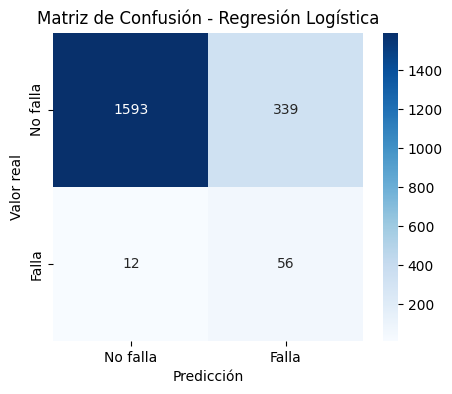

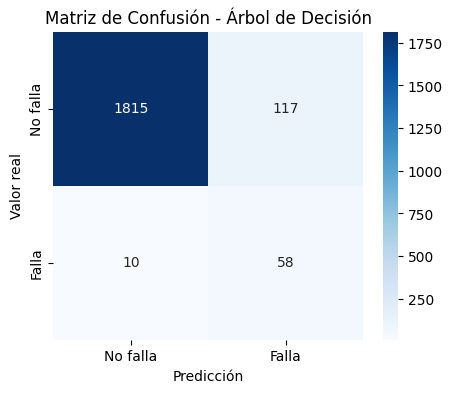

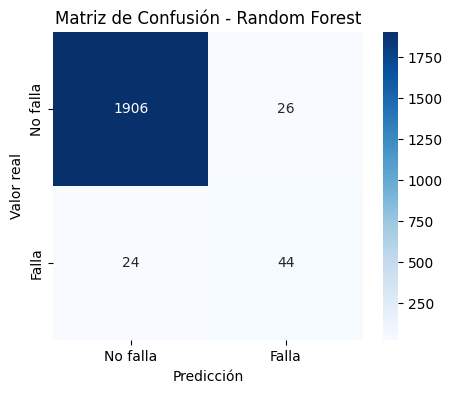

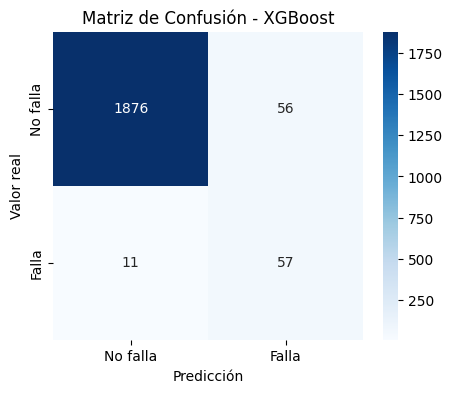

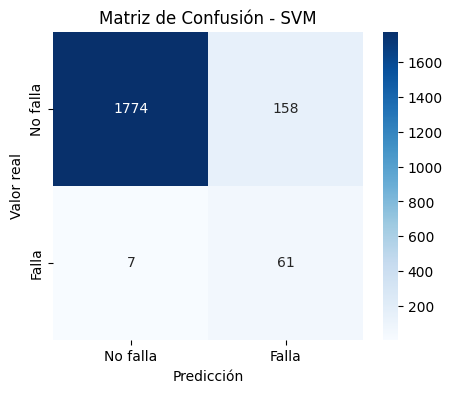

In [27]:
# ============================================================
# 23. MATRICES DE CONFUSIÓN
# ============================================================

# Diccionario con las predicciones
predicciones = {
    "Regresión Logística": pred_logistico,
    "Árbol de Decisión": pred_arbol,
    "Random Forest": pred_random_forest,
    "XGBoost": pred_xgboost,
    "SVM": pred_svm
}

# Generar una matriz para cada modelo
for nombre, prediccion in predicciones.items():

    matriz = confusion_matrix(
        y_test,
        prediccion
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No falla", "Falla"],
        yticklabels=["No falla", "Falla"]
    )

    plt.title(f"Matriz de Confusión - {nombre}")
    plt.xlabel("Predicción")
    plt.ylabel("Valor real")

    plt.show()

In [28]:
# ============================================================
# 24. REPORTES DE CLASIFICACIÓN
# ============================================================

for nombre, prediccion in predicciones.items():

    print("=" * 70)
    print(f"REPORTE: {nombre}")
    print("=" * 70)

    print(
        classification_report(
            y_test,
            prediccion,
            target_names=[
                "No falla",
                "Falla"
            ],
            zero_division=0
        )
    )

REPORTE: Regresión Logística
              precision    recall  f1-score   support

    No falla       0.99      0.82      0.90      1932
       Falla       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000

REPORTE: Árbol de Decisión
              precision    recall  f1-score   support

    No falla       0.99      0.94      0.97      1932
       Falla       0.33      0.85      0.48        68

    accuracy                           0.94      2000
   macro avg       0.66      0.90      0.72      2000
weighted avg       0.97      0.94      0.95      2000

REPORTE: Random Forest
              precision    recall  f1-score   support

    No falla       0.99      0.99      0.99      1932
       Falla       0.63      0.65      0.64        68

    accuracy                           0.97      2000
   macro avg       0.81      0.82      0.81      

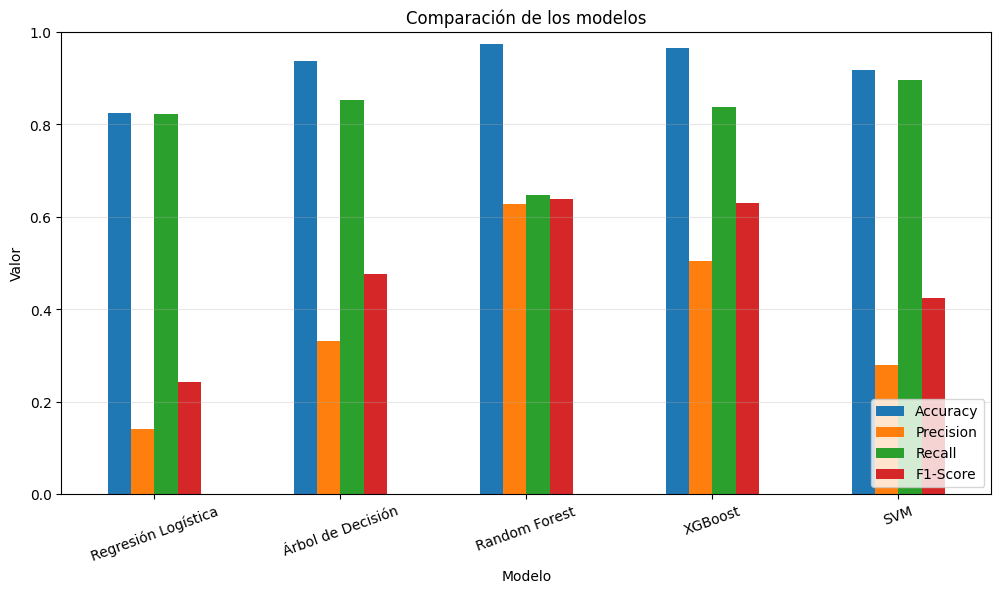

In [29]:
# ============================================================
# 25. COMPARACIÓN DE MODELOS
# ============================================================

# Convertimos la tabla para facilitar la gráfica
resultados_grafica = resultados_df.set_index("Modelo")

# Seleccionamos las métricas
resultados_grafica[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparación de los modelos")
plt.ylabel("Valor")
plt.xlabel("Modelo")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [37]:
# ============================================================
# 26. SELECCIÓN DEL MODELO CON MAYOR RECALL
# ============================================================

mejor_modelo_recall = resultados_df.loc[
    resultados_df["Recall"].idxmax()
]

print("MODELO SELECCIONADO POR MAYOR RECALL:")
print(mejor_modelo_recall)

print("\nCriterio de selección:")
print("Priorizar la detección de la clase positiva (falla).")

MODELO SELECCIONADO POR MAYOR RECALL:
Modelo            SVM
Accuracy       0.9175
Precision    0.278539
Recall       0.897059
F1-Score     0.425087
Name: 4, dtype: object

Criterio de selección:
Priorizar la detección de la clase positiva (falla).


In [38]:
# ============================================================
# 27. GUARDAR MODELO DEFINITIVO SVM
# ============================================================

import joblib

joblib.dump(
    pipeline_svm,
    "modelo_mantenimiento_predictivo.pkl"
)

print("Modelo SVM guardado correctamente.")

Modelo SVM guardado correctamente.


In [32]:
# ============================================================
# 28. NUEVA OBSERVACIÓN
# ============================================================

nueva_observacion = pd.DataFrame({
    "Type": ["M"],
    "Air temperature [K]": [300.0],
    "Process temperature [K]": [310.0],
    "Rotational speed [rpm]": [1500],
    "Torque [Nm]": [50.0],
    "Tool wear [min]": [180]
})

display(nueva_observacion)

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,300.0,310.0,1500,50.0,180


In [39]:
# ============================================================
# 29. PREDICCIÓN DE UNA NUEVA OBSERVACIÓN
# ============================================================

modelos_entrenados = {
    "SVM": pipeline_svm
}

for nombre, modelo in modelos_entrenados.items():

    prediccion = modelo.predict(nueva_observacion)[0]

    if prediccion == 1:
        resultado = "POSIBLE FALLA"
    else:
        resultado = "NO FALLA"

    print(f"{nombre}: {resultado}")

SVM: POSIBLE FALLA


In [40]:
# ============================================================
# 30. PROBABILIDAD DE PREDICCIÓN
# ============================================================

for nombre, modelo in modelos_entrenados.items():

    probabilidades = modelo.predict_proba(
        nueva_observacion
    )[0]

    prob_no_falla = probabilidades[0]
    prob_falla = probabilidades[1]

    print("=" * 60)
    print(nombre)
    print(f"Probabilidad de NO FALLA: {prob_no_falla:.2%}")
    print(f"Probabilidad de FALLA: {prob_falla:.2%}")

SVM
Probabilidad de NO FALLA: 1.17%
Probabilidad de FALLA: 98.83%


In [41]:
# ============================================================
# 31. MODIFICACIÓN DE UNA VARIABLE
# ============================================================

nueva_observacion["Torque [Nm]"] = 70.0

print("Nueva condición operativa:")
display(nueva_observacion)

for nombre, modelo in modelos_entrenados.items():

    prediccion = modelo.predict(nueva_observacion)[0]

    probabilidad_falla = modelo.predict_proba(
        nueva_observacion
    )[0][1]

    resultado = "POSIBLE FALLA" if prediccion == 1 else "NO FALLA"

    print(
        f"{nombre}: "
        f"{resultado} | "
        f"Probabilidad de falla={probabilidad_falla:.2%}"
    )

Nueva condición operativa:


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,300.0,310.0,1500,70.0,180


SVM: POSIBLE FALLA | Probabilidad de falla=98.83%


In [42]:
# ============================================================
# 32. VALIDACIÓN FINAL DEL ENTRENAMIENTO
# ============================================================

print("=" * 50)
print("IMPLEMENTACIÓN FINALIZADA")
print("=" * 50)

print(f"Registros utilizados: {len(df)}")
print(f"Variables de entrada: {len(FEATURES)}")
print("Modelos entrenados: 5")

print("\nModelos evaluados:")

for nombre in predicciones.keys():
    print(f" - {nombre}")

print("\nModelo seleccionado: SVM")
print("Criterio: mayor Recall en la clase falla.")
print("Recall obtenido: 89.71%")

print("\nEl pipeline de Machine Learning funciona correctamente.")

IMPLEMENTACIÓN FINALIZADA
Registros utilizados: 10000
Variables de entrada: 6
Modelos entrenados: 5

Modelos evaluados:
 - Regresión Logística
 - Árbol de Decisión
 - Random Forest
 - XGBoost
 - SVM

Modelo seleccionado: SVM
Criterio: mayor Recall en la clase falla.
Recall obtenido: 89.71%

El pipeline de Machine Learning funciona correctamente.
